<a href="https://colab.research.google.com/github/UlyaBatool/Data_and_sciences/blob/main/Principal_Component_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
#to reduce dimentioanlity we will use PCA, begins we standard imports
# this code is for unsupervised methiod
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()


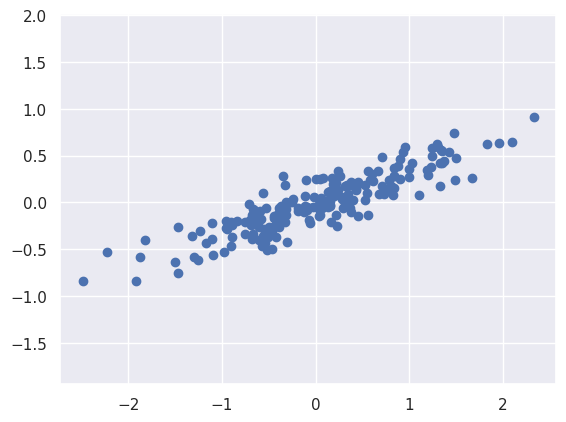

In [14]:
# now we have imported the important imports now we will generate random values and try to if there is any relationship between x and y
rng = np.random.RandomState(1)
X = np.dot(rng.rand(2, 2), rng.randn(2, 200)).T
plt.scatter(X[:, 0], X[:, 1])
plt.axis('equal');



In [16]:
# to find the directionin the data set in axes we use principle axes
# for that use Scikit-Learn’s PCA estimator
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
# Learn the principal axes and their explained variance from X (this basicaly learn the direction and variance in the data set)
pca.fit(X)

PCA(n_components=2)

In [17]:
# now the code
# Display the directions of the two principal axes
print(pca.components_)

# Display the variance captured by each principal component
print(pca.explained_variance_)

[[ 0.94446029  0.32862557]
 [-0.32862557  0.94446029]]
[0.7625315 0.0184779]


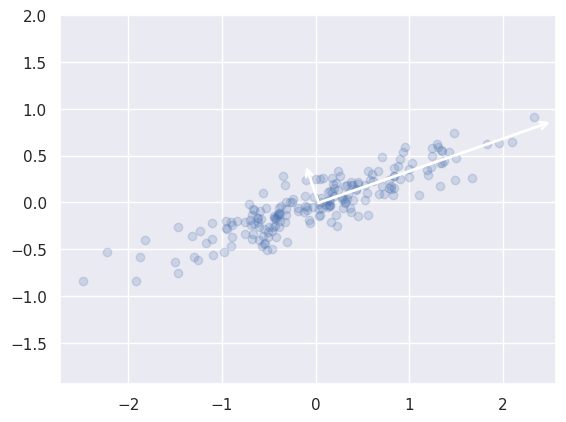

In [18]:
# Define a function to draw an arrow from v0 to v1
def draw_vector(v0, v1, ax=None):
    ax = ax or plt.gca()
    arrowprops = dict(
        arrowstyle='->',
        linewidth=2,
        shrinkA=0,
        shrinkB=0
    )
    ax.annotate('', xy=v1, xytext=v0, arrowprops=arrowprops)

# Plot the original data points with some transparency
plt.scatter(X[:, 0], X[:, 1], alpha=0.2)

# Draw each principal axis as an arrow starting at the data mean
for variance, vector in zip(pca.explained_variance_, pca.components_):
    # Set arrow length to three standard deviations along this axis
    v = vector * 3 * np.sqrt(variance)
    draw_vector(pca.mean_, pca.mean_ + v)

# Use the same scale on both axes to show directions correctly
plt.axis('equal')
plt.show()

In [19]:
pca = PCA(n_components=1)  # Keep only the first principal component
pca.fit(X)                # Learn its direction from the data
X_pca = pca.transform(X)  # Project each point onto that direction

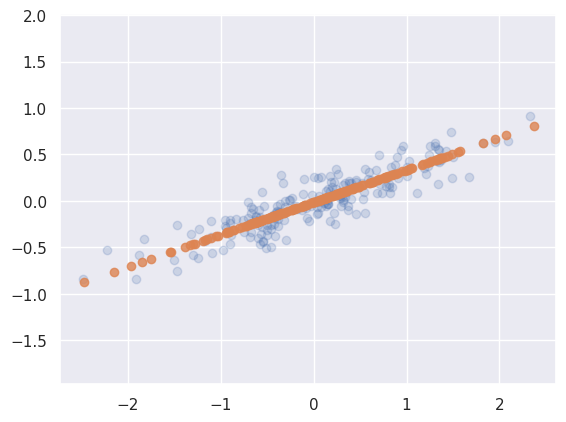

In [20]:
# Reconstruct approximate 2D points from the 1D PCA coordinates
X_new = pca.inverse_transform(X_pca)

# Plot the original points
plt.scatter(X[:, 0], X[:, 1], alpha=0.2)

# Plot the reconstructed points
plt.scatter(X_new[:, 0], X_new[:, 1], alpha=0.8)

# Use the same scale on both axes
plt.axis('equal')
plt.show()

In [21]:
# this will help to understand or look application of PCA to the digits data
from sklearn.datasets import load_digits

digits = load_digits()
digits.data.shape

(1797, 64)

In [22]:
# Create a PCA model to reduce 64 pixel features to 2 principal components
pca = PCA(n_components=2)

# Learn the principal axes and project each image onto them
projected = pca.fit_transform(digits.data)

# Original shape: 1,797 images, each with 64 pixel values
print(digits.data.shape)  # (1797, 64)

# Reduced shape: 1,797 images, each with 2 principal component scores
print(projected.shape)  # (1797, 2)

(1797, 64)
(1797, 2)


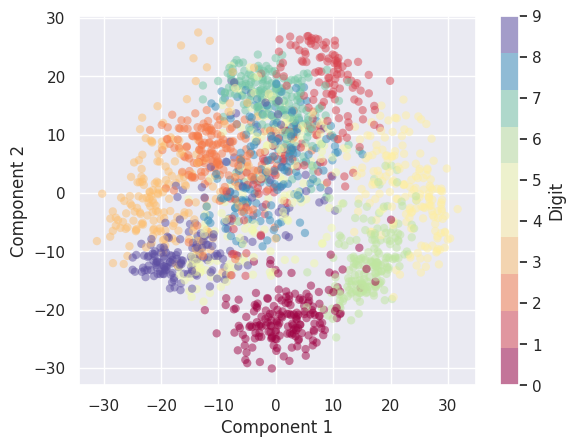

In [23]:
# Plot each digit image using its two PCA coordinates
plt.scatter(
    projected[:, 0],       # First principal component scores: horizontal axis
    projected[:, 1],       # Second principal component scores: vertical axis
    c=digits.target,      # Colour each point by its actual digit (0–9)
    edgecolors='none',    # Remove outlines around the points
    alpha=0.5,            # Make points partly transparent to show overlap
    cmap=plt.get_cmap('Spectral', 10)  # Use 10 colours for the 10 digits
)

# Label the axes
plt.xlabel('Component 1')
plt.ylabel('Component 2')

# Show which colour represents each digit
plt.colorbar(ticks=range(10), label='Digit')
plt.show()

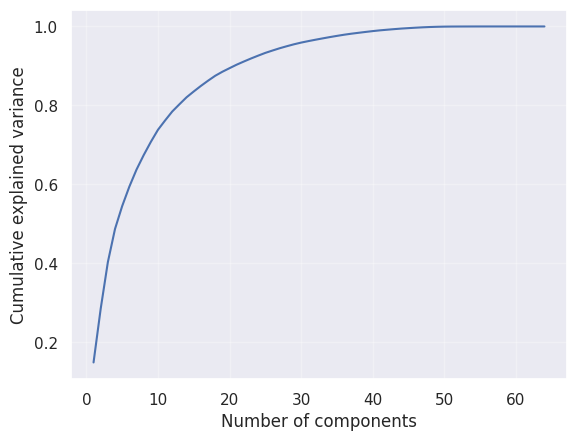

In [24]:
# Fit PCA without restricting the number of components
pca = PCA().fit(digits.data)

# Add up the explained variance ratios in component order
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

# Number components from 1 so the horizontal axis matches the count
component_numbers = np.arange(1, len(cumulative_variance) + 1)

# Plot how much variance is retained as more components are included
plt.plot(component_numbers, cumulative_variance)

plt.xlabel('Number of components')
plt.ylabel('Cumulative explained variance')
plt.grid(alpha=0.3)
plt.show()

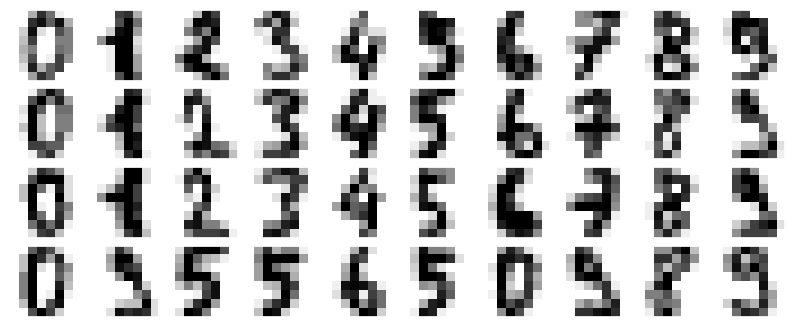

In [25]:
# Define a function to display the first 40 digit images
def plot_digits(data):
    # Create a grid of 4 rows and 10 columns
    fig, axes = plt.subplots(
        4, 10,
        figsize=(10, 4),
        subplot_kw={'xticks': [], 'yticks': []},  # Hide axis tick marks
        gridspec_kw={'hspace': 0.1, 'wspace': 0.1}  # Space between images
    )

    # Loop through the 40 plotting panels
    for i, ax in enumerate(axes.flat):
        # Reshape each row of 64 pixel values into an 8 × 8 image
        ax.imshow(
            data[i].reshape(8, 8),
            cmap='binary',           # Display in white and black
            interpolation='nearest', # Show pixels without smoothing
            clim=(0, 16)             # Use the same brightness scale throughout
        )

    plt.show()

# Display the first 40 original digit images
plot_digits(digits.data)

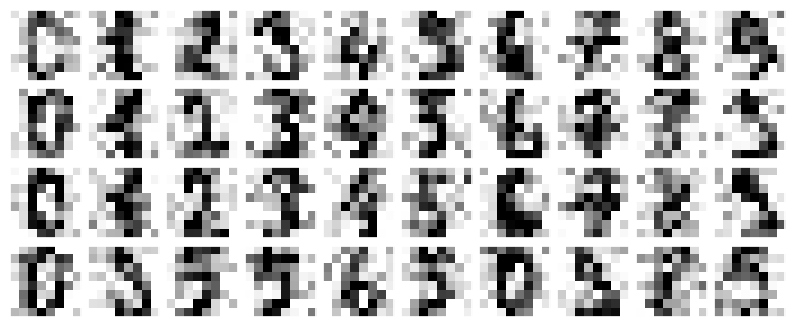

In [26]:
# Make the random noise reproducible
np.random.seed(42)

# Generate noisy pixel values centred on the original values,
# with a standard deviation of 4
noisy = np.random.normal(digits.data, 4)

# Display the first 40 noisy images using the function defined earlier
plot_digits(noisy)

12


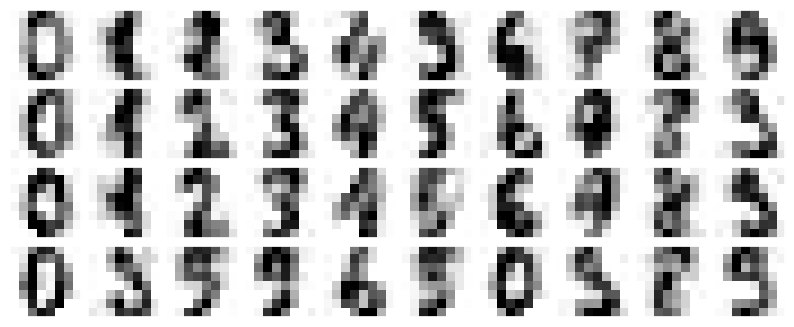

In [27]:
# Fit PCA and retain enough components to explain at least 50% of the variance
pca = PCA(n_components=0.50).fit(noisy)

# Display how many components were selected: 12 in this example
print(pca.n_components_)

# Reduce each noisy image from 64 pixel values to 12 component scores
components = pca.transform(noisy)

# Reconstruct approximate images with 64 pixel values each
filtered = pca.inverse_transform(components)

# Display the reconstructed images
plot_digits(filtered)

In [28]:
from sklearn.datasets import fetch_lfw_people

# Load people who have at least 60 images in the dataset
faces = fetch_lfw_people(min_faces_per_person=60)

# Display the names of the people included
print(faces.target_names)

# Display the number of images, image height, and image width
print(faces.images.shape)

['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Junichiro Koizumi' 'Tony Blair']
(1348, 62, 47)


In [29]:
from sklearn.decomposition import PCA

# Create a PCA model that learns 150 principal axes
pca = PCA(
    n_components=150,
    svd_solver='randomized',
    random_state=42
)

# Learn patterns of pixel variation across the face images
pca.fit(faces.data)

PCA(n_components=150, random_state=42, svd_solver='randomized')

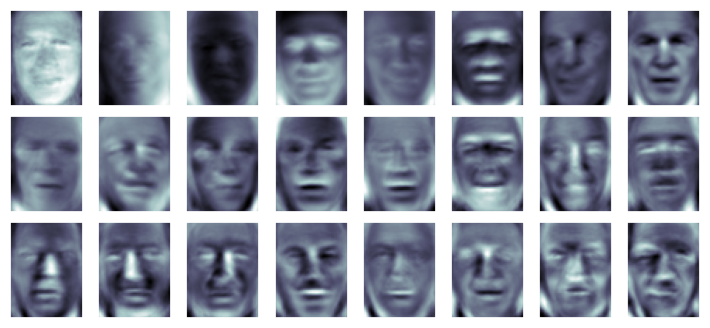

In [30]:
import matplotlib.pyplot as plt

# Get the image dimensions directly from the dataset
height, width = faces.images.shape[1:]

# Create 24 panels arranged in 3 rows and 8 columns
fig, axes = plt.subplots(
    3, 8,
    figsize=(9, 4),
    subplot_kw={'xticks': [], 'yticks': []},
    gridspec_kw={'hspace': 0.1, 'wspace': 0.1}
)

# Display the first 24 principal axes as face-shaped images
for i, ax in enumerate(axes.flat):
    ax.imshow(
        pca.components_[i].reshape(height, width),
        cmap='bone'
    )

plt.show()

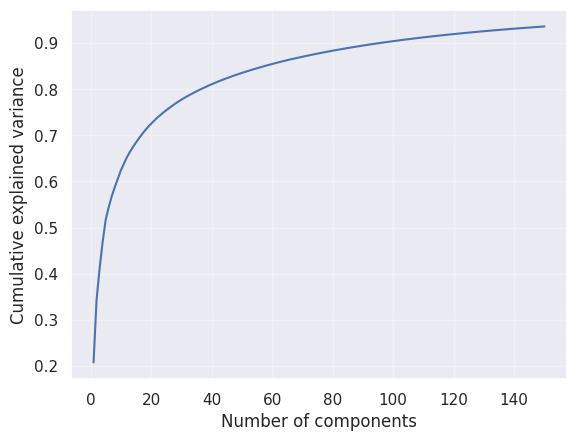

In [32]:
# Add together the variance ratios of successive components
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

# Number the components from 1 to 150
component_numbers = np.arange(1, len(cumulative_variance) + 1)

# Plot the total variance retained as more components are included
plt.plot(component_numbers, cumulative_variance)

plt.xlabel('Number of components')
plt.ylabel('Cumulative explained variance')
plt.grid(alpha=0.3)
plt.show()

In [33]:
# Represent each face using 150 principal component scores
components = pca.transform(faces.data)

# Convert those scores back into approximate pixel values
projected = pca.inverse_transform(components)

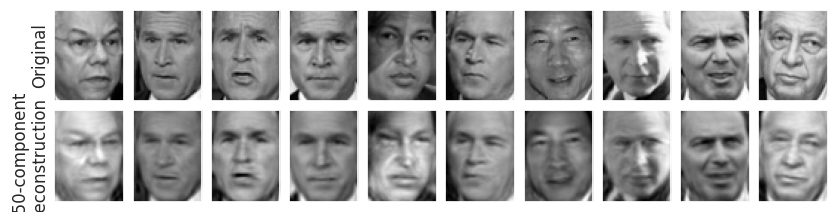

In [34]:
# Get the face image dimensions
height, width = faces.images.shape[1:]

# Create two rows of ten images without axis ticks
fig, ax = plt.subplots(
    2, 10,
    figsize=(10, 2.5),
    subplot_kw={'xticks': [], 'yticks': []},
    gridspec_kw={'hspace': 0.1, 'wspace': 0.1}
)

for i in range(10):
    # Top row: original face
    ax[0, i].imshow(
        faces.data[i].reshape(height, width),
        cmap='binary_r'
    )

    # Bottom row: face reconstructed from 150 PCA scores
    ax[1, i].imshow(
        projected[i].reshape(height, width),
        cmap='binary_r'
    )

# Label the two rows
ax[0, 0].set_ylabel('Original')
ax[1, 0].set_ylabel('150-component\nreconstruction')

plt.show()